# Lab 08 - Handwritten digit recognition with a CNN
AI-101L, Arham. Kaggle Digit Recognizer data (42,000 labelled 28x28 images). Data CSVs are not committed (76 MB); put `train.csv` and `test.csv` in `data/`.

In [1]:
import os, warnings; os.environ['TF_CPP_MIN_LOG_LEVEL']='2'; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
tf.keras.utils.set_random_seed(42)
print('TensorFlow', tf.__version__)

I0000 00:00:1793882004.502174     203 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793882005.910992     203 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Load and prepare
Scale pixels 0-255 to 0-1 and reshape each row of 784 numbers to a 28x28x1 image. Stratified 80/20 split keeps the digit mix equal in both parts.

In [2]:
df = pd.read_csv('data/train.csv')
print(df.shape)
print(df['label'].value_counts().sort_index().to_dict())
y = df['label'].values
X = (df.drop(columns='label').values.astype('float32')/255.0).reshape(-1,28,28,1)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_val.shape)

(42000, 785)
{0: 4132, 1: 4684, 2: 4177, 3: 4351, 4: 4072, 5: 3795, 6: 4137, 7: 4401, 8: 4063, 9: 4188}


(33600, 28, 28, 1) (8400, 28, 28, 1)


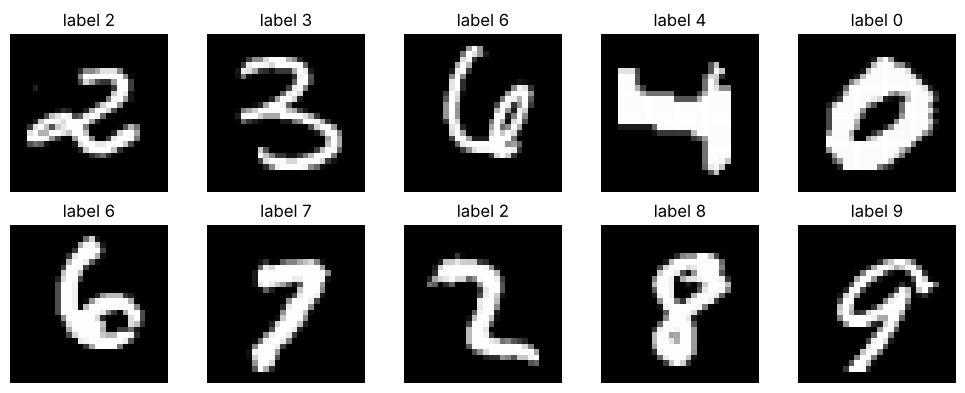

In [3]:
fig, ax = plt.subplots(2,5,figsize=(10,4))
for i,a in enumerate(ax.ravel()):
    a.imshow(X_train[i].reshape(28,28), cmap='gray'); a.set_title(f'label {y_train[i]}'); a.axis('off')
plt.tight_layout(); plt.savefig('figures/samples.png',dpi=120); plt.show()

## 2. Model
Two convolution + max-pool blocks (32 then 64 filters, 3x3), then Flatten, Dense 128 with 30% dropout, and a 10-way softmax. Same design as the lab spec.

In [4]:
model = models.Sequential([
    layers.Input(shape=(28,28,1)),
    layers.Conv2D(32,(3,3),activation='relu'), layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3),activation='relu'), layers.MaxPooling2D((2,2)),
    layers.Flatten(), layers.Dense(128,activation='relu'), layers.Dropout(0.3),
    layers.Dense(10,activation='softmax')])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Train

In [5]:
history = model.fit(X_train, y_train, epochs=10, batch_size=64, validation_data=(X_val,y_val), verbose=2)
model.save('mnist_cnn_model.keras')

Epoch 1/10


525/525 - 9s - 17ms/step - accuracy: 0.9227 - loss: 0.2553 - val_accuracy: 0.9767 - val_loss: 0.0795


Epoch 2/10


525/525 - 8s - 15ms/step - accuracy: 0.9757 - loss: 0.0773 - val_accuracy: 0.9815 - val_loss: 0.0569


Epoch 3/10


525/525 - 8s - 16ms/step - accuracy: 0.9829 - loss: 0.0547 - val_accuracy: 0.9858 - val_loss: 0.0483


... (10 outputs left out)

Epoch 9/10


525/525 - 10s - 19ms/step - accuracy: 0.9944 - loss: 0.0168 - val_accuracy: 0.9870 - val_loss: 0.0495


Epoch 10/10


525/525 - 7s - 13ms/step - accuracy: 0.9943 - loss: 0.0168 - val_accuracy: 0.9870 - val_loss: 0.0444


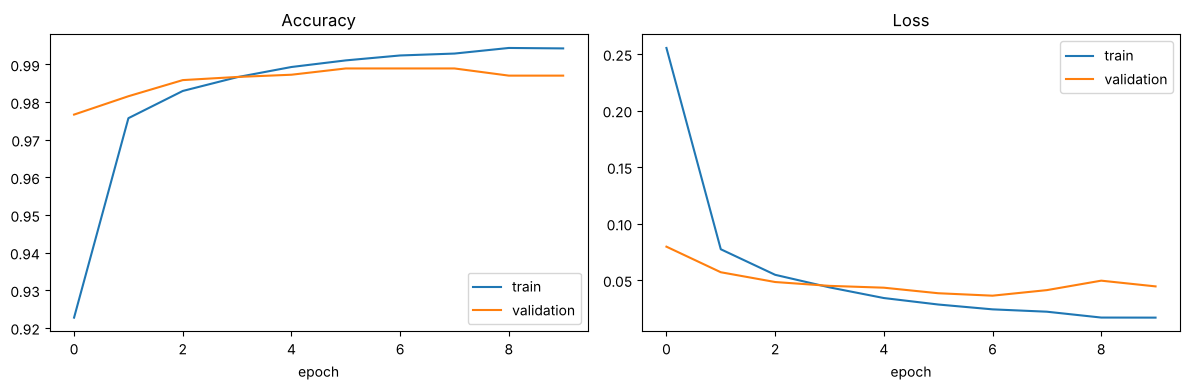

lowest validation loss at epoch 7 | final train acc 0.9943, final val acc 0.9870


In [6]:
h = history.history
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(h['accuracy'],label='train'); ax[0].plot(h['val_accuracy'],label='validation'); ax[0].set_title('Accuracy'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(h['loss'],label='train'); ax[1].plot(h['val_loss'],label='validation'); ax[1].set_title('Loss'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.savefig('figures/training_curves.png',dpi=120); plt.show()
best = int(np.argmin(h['val_loss'])); print('lowest validation loss at epoch', best+1, '| final train acc %.4f, final val acc %.4f' % (h['accuracy'][-1], h['val_accuracy'][-1]))

## 4. Where does it go wrong?

validation accuracy: 0.987


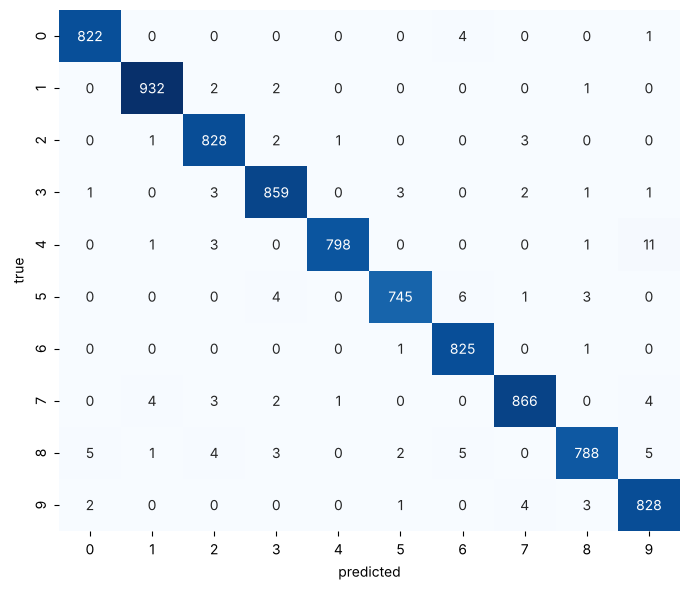

              precision    recall  f1-score   support

           0     0.9904    0.9940    0.9922       827
           1     0.9925    0.9947    0.9936       937
           2     0.9822    0.9916    0.9869       835
           3     0.9851    0.9874    0.9862       870
           4     0.9975    0.9803    0.9888       814
           5     0.9907    0.9816    0.9861       759
           6     0.9821    0.9976    0.9898       827
           7     0.9886    0.9841    0.9863       880
           8     0.9875    0.9692    0.9783       813
           9     0.9741    0.9881    0.9810       838

    accuracy                         0.9870      8400
   macro avg     0.9871    0.9868    0.9869      8400
weighted avg     0.9871    0.9870    0.9870      8400



In [7]:
pred = model.predict(X_val, verbose=0).argmax(1)
print('validation accuracy:', round(float((pred==y_val).mean()),4))
cm = confusion_matrix(y_val, pred)
plt.figure(figsize=(7,6)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('predicted'); plt.ylabel('true'); plt.tight_layout(); plt.savefig('figures/confusion_matrix.png',dpi=120); plt.show()
print(classification_report(y_val, pred, digits=4))

most common mix-ups (count, true, predicted): [(np.int64(11), 4, 9), (np.int64(6), 5, 6), (np.int64(5), 8, 9), (np.int64(5), 8, 6), (np.int64(5), 8, 0)]


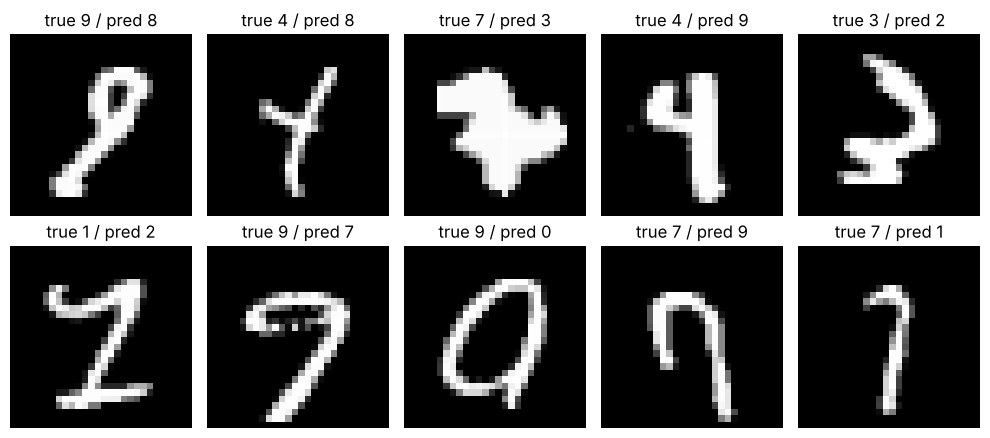

In [8]:
off = cm.copy(); np.fill_diagonal(off,0)
top = sorted([(off[i,j],i,j) for i in range(10) for j in range(10) if off[i,j]], reverse=True)[:5]
print('most common mix-ups (count, true, predicted):', top)
wrong = np.where(pred!=y_val)[0][:10]
fig, ax = plt.subplots(2,5,figsize=(10,4.5))
for a,i in zip(ax.ravel(), wrong):
    a.imshow(X_val[i].reshape(28,28),cmap='gray'); a.set_title(f'true {y_val[i]} / pred {pred[i]}'); a.axis('off')
plt.tight_layout(); plt.savefig('figures/misclassified.png',dpi=120); plt.show()

## 5. Check the model file submitted earlier
`mnist_cnn_model_submitted.keras` is the model saved from the original notebook run. Both runs use the same stratified split (`random_state=42`), so its validation images were unseen by it too and the two scores are directly comparable. The 0.9893 matches the final validation accuracy printed in that original run.

In [9]:
old = tf.keras.models.load_model('mnist_cnn_model_submitted.keras')
old_pred = old.predict(X_val, verbose=0).argmax(1)
print('submitted model  val acc:', round(float((old_pred==y_val).mean()),4), '| params', old.count_params())
print('retrained model  val acc:', round(float((pred==y_val).mean()),4), '| params', model.count_params())
print('agree on', round(float((old_pred==pred).mean())*100,2), '% of validation images')

submitted model  val acc: 0.9893 | params 225034
retrained model  val acc: 0.987 | params 225034
agree on 98.79 % of validation images


## 6. Predict on unseen test images

(28000, 28, 28, 1)


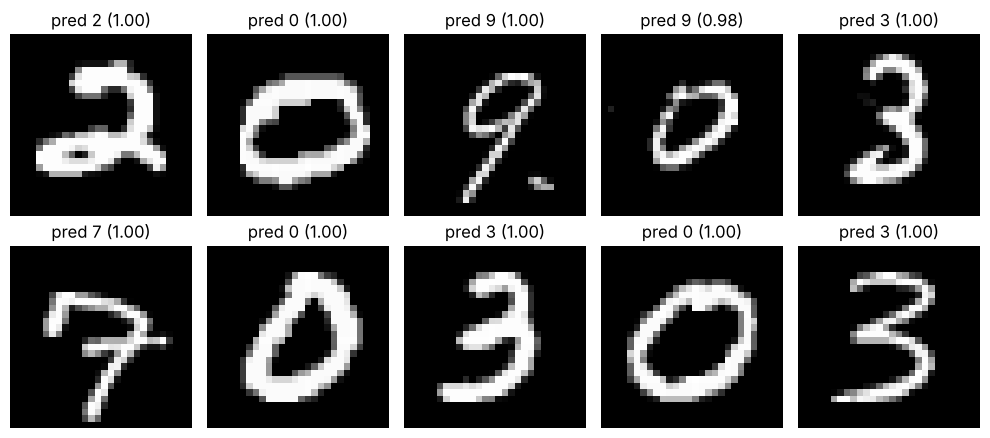

test images with confidence below 90%: 615 of 28000


In [10]:
test = pd.read_csv('data/test.csv'); X_test = (test.values.astype('float32')/255.0).reshape(-1,28,28,1)
print(X_test.shape)
probs = model.predict(X_test[:10], verbose=0)
fig, ax = plt.subplots(2,5,figsize=(10,4.5))
for k,a in enumerate(ax.ravel()):
    a.imshow(X_test[k].reshape(28,28),cmap='gray'); a.set_title(f'pred {probs[k].argmax()} ({probs[k].max():.2f})'); a.axis('off')
plt.tight_layout(); plt.savefig('figures/test_predictions.png',dpi=120); plt.show()
conf = model.predict(X_test, verbose=0).max(1)
print('test images with confidence below 90%:', int((conf<0.9).sum()), 'of', len(conf))

## 7. My own handwritten digit
The MNIST images are white digits on black; a photo or screenshot is usually dark ink on white. So the picture is converted to grey, inverted, cropped to the ink, scaled so the longer side is 20 px, and centred in a 28x28 frame (how MNIST itself was prepared).

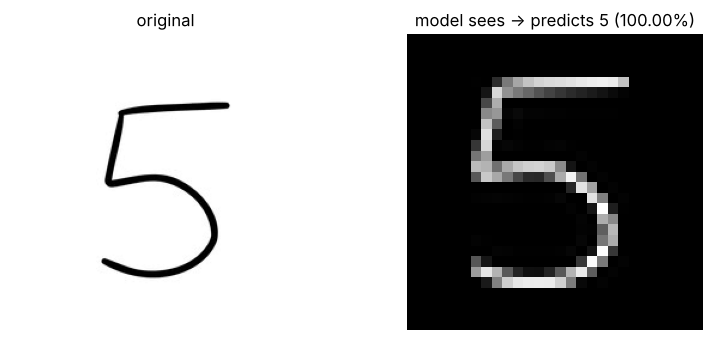

probabilities: {0: 0.0, 1: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 1.0, 6: 0.0, 7: 0.0, 8: 0.0, 9: 0.0}


In [11]:
from PIL import Image, ImageOps
def prepare(path):
    g = ImageOps.invert(Image.open(path).convert('L'))
    box = g.point(lambda p: 255 if p>40 else 0).getbbox(); g = g.crop(box)
    s = 20/max(g.size); g = g.resize((max(1,round(g.width*s)), max(1,round(g.height*s))), Image.LANCZOS)
    canvas = Image.new('L',(28,28),0); canvas.paste(g, ((28-g.width)//2,(28-g.height)//2)); return np.asarray(canvas,dtype='float32')/255.0
img = prepare('images/handwritten_5.png'); p = model.predict(img.reshape(1,28,28,1), verbose=0)[0]
fig, ax = plt.subplots(1,2,figsize=(8,3.5)); ax[0].imshow(Image.open('images/handwritten_5.png').convert('L'),cmap='gray'); ax[0].set_title('original'); ax[0].axis('off')
ax[1].imshow(img,cmap='gray'); ax[1].set_title(f'model sees -> predicts {p.argmax()} ({p.max():.2%})'); ax[1].axis('off'); plt.tight_layout(); plt.savefig('figures/handwritten_prediction.png',dpi=120); plt.show()
print('probabilities:', {i: round(float(v),4) for i,v in enumerate(p)})